# CCA 3: Computer Vision Assignment

## Task 2: Feature Extraction and Image Matching

**Unit:** Unit 4  
**Programming Language:** Python  
**Libraries:** OpenCV, NumPy, Matplotlib, scikit-image

### 1. Introduction

Feature extraction is an important process in computer vision. It identifies useful information such as edges, shapes, corners and patterns from an image.

In this task, Histogram of Oriented Gradients (HOG) and Scale-Invariant Feature Transform (SIFT) will be implemented to extract and match image features.

### 2. Objectives

1. Extract and visualize HOG features.
2. Detect SIFT keypoints in images.
3. Calculate SIFT feature descriptors.
4. Match SIFT features between two images.
5. Repeat feature matching after rotating or resizing an image.
6. Compare the matching results.

### 3. Expected Outcomes

The experiment will generate HOG visualizations, SIFT keypoint visualizations, feature descriptors and image-matching results. The matching performance will be compared before and after image transformations.

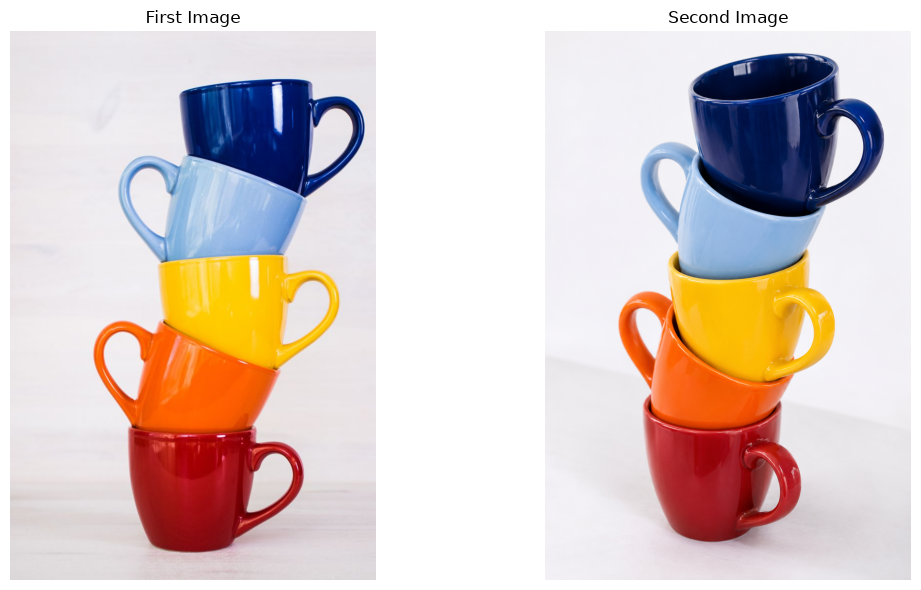

Both images loaded successfully!
First image dimensions: (1104, 736, 3)
Second image dimensions: (1535, 1025, 3)


In [1]:
# Task 2: Library Imports and Image Loading

import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from skimage.feature import hog

# Define image paths
IMAGE_PATH_1 = Path("dataset/images/original.jpg")
IMAGE_PATH_2 = Path("dataset/images/second.png")

# Load images using OpenCV
image1 = cv2.imread(str(IMAGE_PATH_1))
image2 = cv2.imread(str(IMAGE_PATH_2))

# Check whether images exist
if image1 is None:
    raise FileNotFoundError(f"First image not found: {IMAGE_PATH_1}")

if image2 is None:
    raise FileNotFoundError(f"Second image not found: {IMAGE_PATH_2}")

# Convert BGR to RGB
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

# Convert images to grayscale
gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

# Display both images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image1_rgb)
plt.title("First Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2_rgb)
plt.title("Second Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Both images loaded successfully!")
print("First image dimensions:", image1.shape)
print("Second image dimensions:", image2.shape)

## Experiment 1: Histogram of Oriented Gradients (HOG)

### Objective
To extract and visualize image features using the Histogram of Oriented Gradients (HOG) technique.

### Theory
HOG is a feature extraction technique that represents an image using the distribution of gradient directions. It captures important structural information such as edges, boundaries and shapes.

### Procedure
1. Convert the input images into grayscale.
2. Calculate HOG features.
3. Generate HOG visualizations.
4. Compare the extracted features from both images.

### Expected Output
HOG feature visualizations for the first and second photographs.


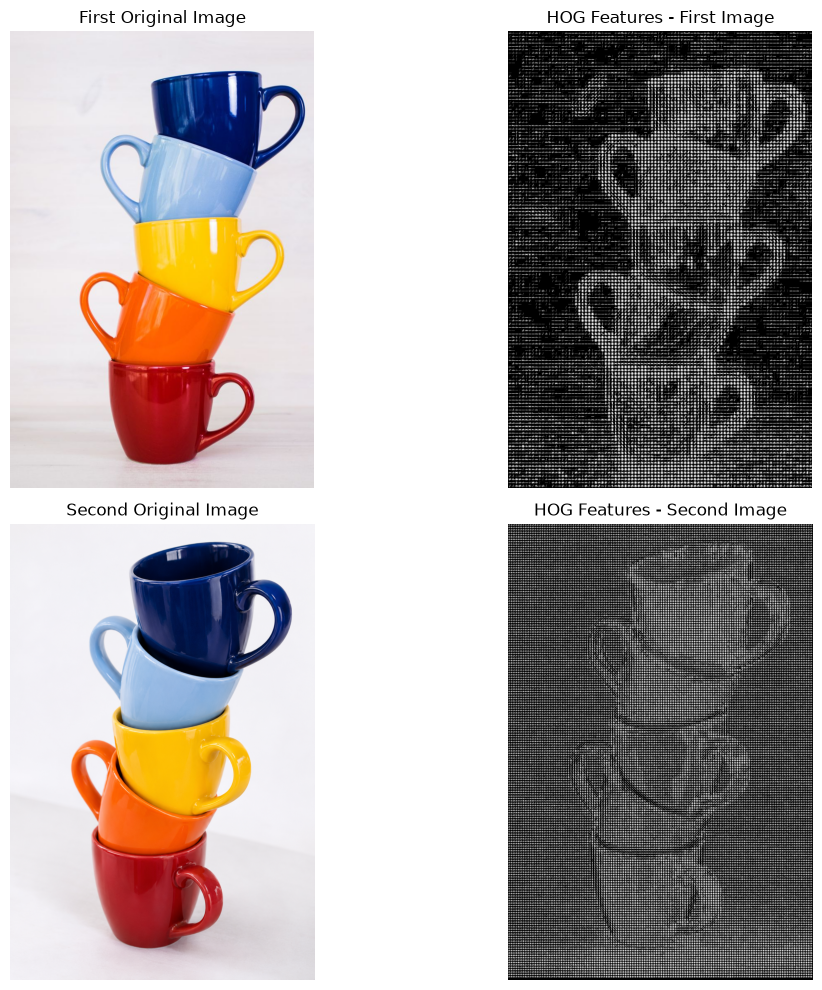

HOG extraction completed successfully!
First image HOG descriptor length: 448812
Second image HOG descriptor length: 868680
HOG results saved successfully!
HOG extraction completed successfully!
First image HOG descriptor length: 448812
Second image HOG descriptor length: 868680


In [9]:
# Experiment 1: HOG Feature Extraction

from skimage.feature import hog
from skimage import exposure

# Calculate HOG features for first image
features1, hog_image1 = hog(
    gray1,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm="L2-Hys"
)

# Calculate HOG features for second image
features2, hog_image2 = hog(
    gray2,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm="L2-Hys"
)

# Improve visualization contrast
hog_image1 = exposure.rescale_intensity(
    hog_image1, in_range=(0, 0.3)
)

hog_image2 = exposure.rescale_intensity(
    hog_image2, in_range=(0, 0.3)
)

# Display original images and HOG visualizations
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(image1_rgb)
plt.title("First Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(hog_image1, cmap="gray")
plt.title("HOG Features - First Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image2_rgb)
plt.title("Second Original Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(hog_image2, cmap="gray")
plt.title("HOG Features - Second Image")
plt.axis("off")

plt.tight_layout()

# Save HOG visualization
from pathlib import Path

output_dir = Path("outputs/task2")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "hog_feature_extraction.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save HOG feature descriptors
import numpy as np

np.save(output_dir / "hog_features_first.npy", features1)
np.save(output_dir / "hog_features_second.npy", features2)

print("HOG extraction completed successfully!")
print("First image HOG descriptor length:", len(features1))
print("Second image HOG descriptor length:", len(features2))
print("HOG results saved successfully!")

print("HOG extraction completed successfully!")
print("First image HOG descriptor length:", len(features1))
print("Second image HOG descriptor length:", len(features2))


### Observations

1. HOG features were successfully extracted from both input images.
2. The images were converted into grayscale before feature extraction.
3. Gradient orientations helped identify edges, boundaries and structural patterns.
4. The cup handles and outer boundaries are visible in the HOG visualizations.
5. Differences in camera angle and object position produced different HOG feature patterns.

### Result

The HOG algorithm successfully extracted shape and edge information from both photographs. The experiment demonstrates how gradient-based features represent the structural characteristics of objects in images.

## Experiment 2: SIFT Keypoint Detection and Feature Descriptors

### Objective
To detect distinctive keypoints and extract feature descriptors from two input images using the SIFT algorithm.

### Theory
Scale-Invariant Feature Transform (SIFT) is a feature detection and description technique used in computer vision. It identifies distinctive image locations and generates descriptors that can be used to compare images.

SIFT is designed to handle changes in image scale and rotation, making it useful for image matching.

### Procedure
1. Convert both images into grayscale.
2. Create a SIFT detector.
3. Detect keypoints in both images.
4. Calculate feature descriptors.
5. Visualize the detected keypoints.

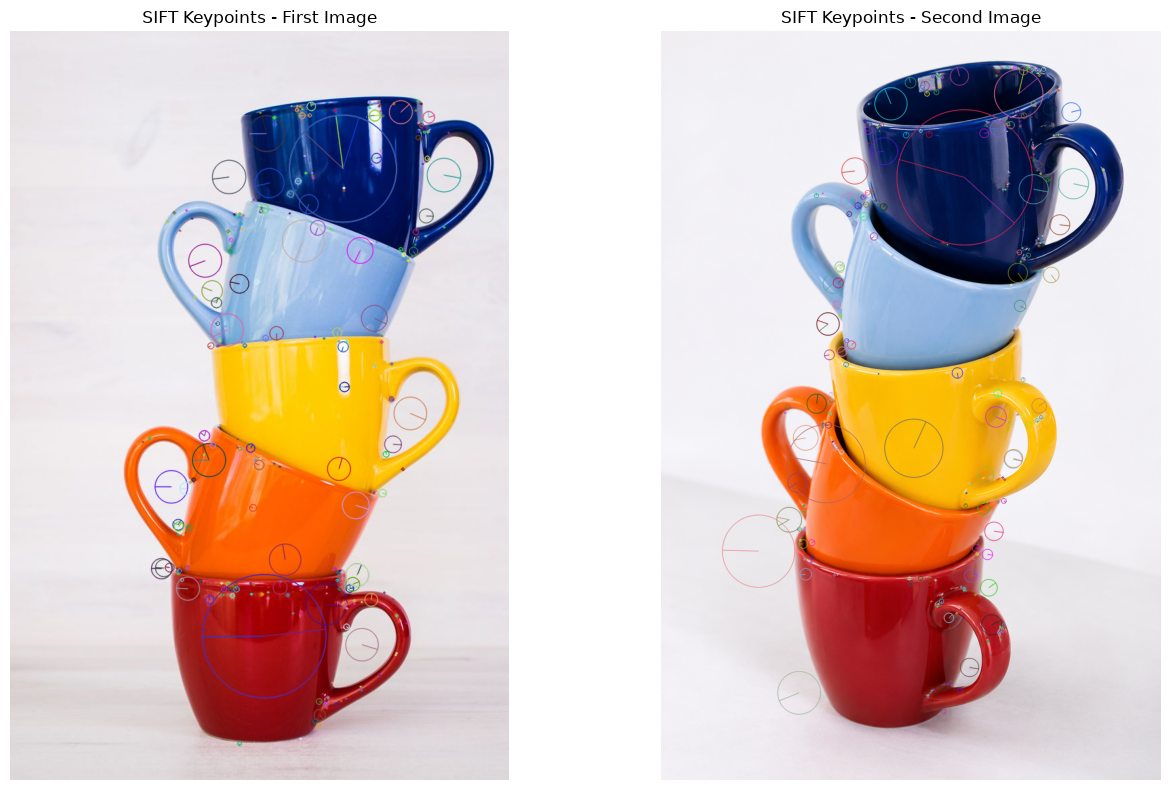

SIFT detection completed successfully!
First image keypoints: 321
Second image keypoints: 336
First image descriptor shape: (321, 128)
Second image descriptor shape: (336, 128)


In [10]:
# Experiment 2: SIFT Keypoint Detection

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

# Draw keypoints on both images
sift_image1 = cv2.drawKeypoints(
    image1_rgb,
    keypoints1,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

sift_image2 = cv2.drawKeypoints(
    image2_rgb,
    keypoints2,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display results
plt.figure(figsize=(14, 8))

plt.subplot(1, 2, 1)
plt.imshow(sift_image1)
plt.title("SIFT Keypoints - First Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sift_image2)
plt.title("SIFT Keypoints - Second Image")
plt.axis("off")

plt.tight_layout()

# Create Task 2 output folder
from pathlib import Path

output_dir = Path("outputs/task2")
output_dir.mkdir(parents=True, exist_ok=True)

# Save SIFT keypoint visualization
plt.savefig(
    output_dir / "sift_keypoints.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save SIFT descriptors
import numpy as np

np.save(output_dir / "sift_descriptors_first.npy", descriptors1)
np.save(output_dir / "sift_descriptors_second.npy", descriptors2)

# Display keypoint information
print("SIFT detection completed successfully!")
print("First image keypoints:", len(keypoints1))
print("Second image keypoints:", len(keypoints2))
print("First image descriptor shape:", descriptors1.shape if descriptors1 is not None else None)
print("Second image descriptor shape:", descriptors2.shape if descriptors2 is not None else None)

### Observations

1. SIFT successfully detected keypoints in both photographs.
2. Keypoints were identified around cup handles, rims, edges and surface patterns.
3. Each detected keypoint was assigned a scale and orientation.
4. The second photograph produced a different keypoint distribution because of changes in camera angle and object positioning.
5. SIFT descriptors provide numerical representations of the detected keypoints for further image matching.

### Result

SIFT keypoint detection and descriptor extraction were successfully performed on both images. The detected keypoints will be used in the next experiment to identify matching features between the photographs.


## Experiment 3: SIFT Feature Matching

### Objective
To identify and match corresponding keypoints between two photographs using SIFT descriptors and the Brute-Force Matcher.

### Theory
Feature matching identifies corresponding visual features between two images.

The Brute-Force Matcher compares feature descriptors and finds the closest matches. Lowe's ratio test is used to filter unreliable matches and retain more distinctive correspondences.

<Figure size 1800x1000 with 0 Axes>

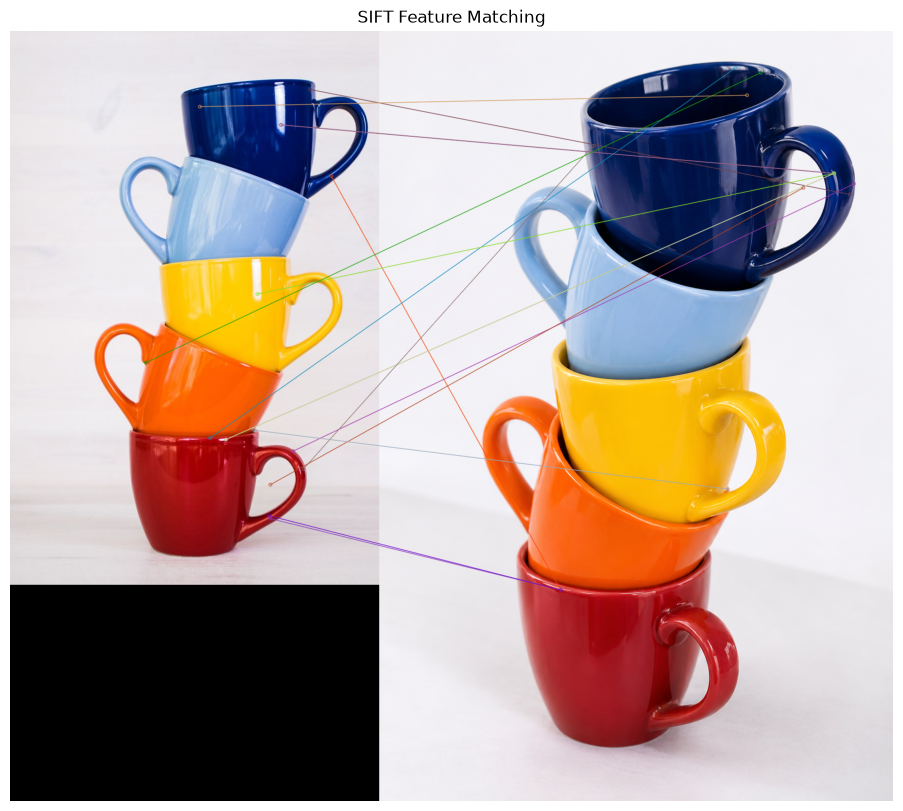

Feature matching completed!
Total initial matches: 321
Good matches after Lowe's ratio test: 16


In [11]:
# Experiment 3: SIFT Feature Matching

# Check whether descriptors are available
if descriptors1 is None or descriptors2 is None:
    raise ValueError("SIFT descriptors could not be extracted.")

# Create Brute-Force matcher
bf = cv2.BFMatcher(cv2.NORM_L2)

# Find two nearest matches for each descriptor
matches = bf.knnMatch(
    descriptors1,
    descriptors2,
    k=2
)

# Apply Lowe's ratio test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

# Sort matches by distance
good_matches = sorted(
    good_matches,
    key=lambda x: x.distance
)

# Draw matching keypoints
matching_image = cv2.drawMatches(
    image1_rgb,
    keypoints1,
    image2_rgb,
    keypoints2,
    good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display matching results
plt.figure(figsize=(18, 10))
# Save SIFT feature matching visualization
from pathlib import Path

output_dir = Path("outputs/task2")
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(18, 10))
plt.imshow(matching_image)
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.savefig(
    output_dir / "sift_feature_matching.jpg",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save matching statistics
import pandas as pd

matching_results = pd.DataFrame({
    "Parameter": [
        "Total initial matches",
        "Good matches after Lowe's ratio test"
    ],
    "Value": [
        len(matches),
        len(good_matches)
    ]
})

matching_results.to_csv(
    output_dir / "sift_matching_results.csv",
    index=False
)

# Print matching information
print("Feature matching completed!")
print("Total initial matches:", len(matches))
print("Good matches after Lowe's ratio test:", len(good_matches))


### Observations

1. SIFT descriptors were compared using the Brute-Force Matcher.
2. The K-nearest neighbour matching method was used to identify two candidate matches for each descriptor.
3. Lowe's ratio test with a threshold of 0.75 was applied to filter ambiguous matches.
4. Matching lines were observed between distinctive regions of the two photographs.
5. Some incorrect matches were visible because of differences in camera angle, object positioning and appearance.

### Result

SIFT feature matching was successfully implemented using the Brute-Force Matcher and Lowe's ratio test. The experiment demonstrated how local image descriptors can identify potential correspondences between two photographs.

## Experiment 4: SIFT Matching After Rotation and Resizing

### Objective

To evaluate the performance of SIFT feature matching when an image undergoes rotation and resizing.

### Theory

SIFT is designed to identify distinctive features despite changes in image scale and orientation.

In this experiment, the original image will be rotated by 30 degrees and resized to 75% of its original dimensions. SIFT keypoints and descriptors will be extracted from the transformed images and compared with those of the original image.

### Procedure

1. Select the original photograph.
2. Rotate it by 30 degrees.
3. Resize it to 75% of its original dimensions.
4. Extract SIFT descriptors from the transformed images.
5. Match the descriptors against the original image.
6. Compare the number of good matches.

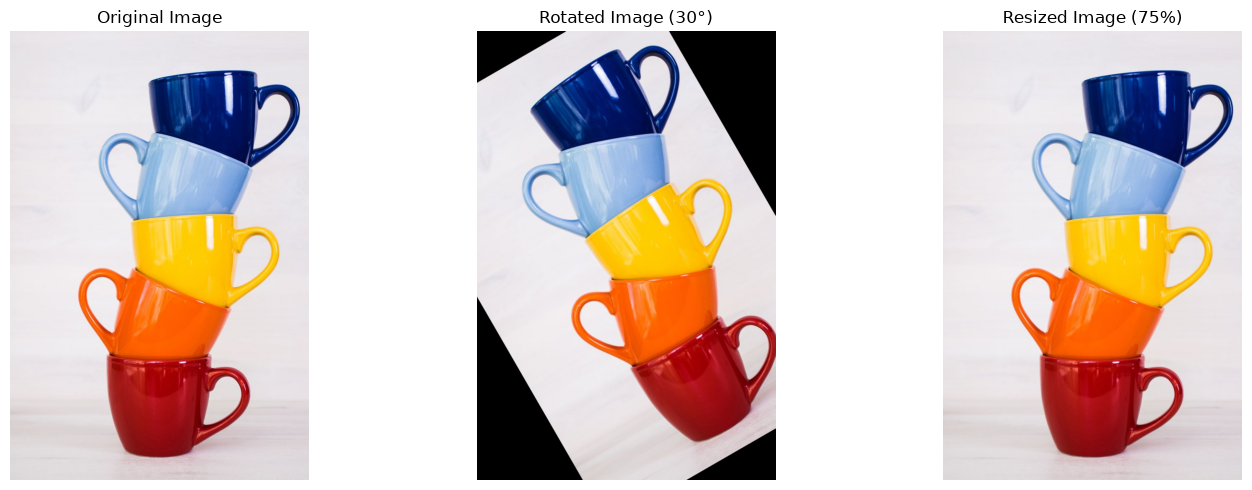

Transformed images saved successfully!
Image rotation completed!
Image resizing completed!
Original dimensions: (1104, 736, 3)
Resized dimensions: (828, 552, 3)


In [12]:
# Experiment 4: Image Rotation and Resizing

# Original image dimensions
height, width = gray1.shape

# --------------------------------
# 1. Rotate original image by 30°
# --------------------------------

rotation_matrix = cv2.getRotationMatrix2D(
    (width // 2, height // 2),
    30,
    1.0
)

rotated_image = cv2.warpAffine(
    image1,
    rotation_matrix,
    (width, height)
)

rotated_gray = cv2.cvtColor(
    rotated_image,
    cv2.COLOR_BGR2GRAY
)

# --------------------------------
# 2. Resize original image to 75%
# --------------------------------

resized_image = cv2.resize(
    image1,
    None,
    fx=0.75,
    fy=0.75,
    interpolation=cv2.INTER_AREA
)

resized_gray = cv2.cvtColor(
    resized_image,
    cv2.COLOR_BGR2GRAY
)

# --------------------------------
# 3. Display transformed images
# --------------------------------

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image1_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB))
plt.title("Rotated Image (30°)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.title("Resized Image (75%)")
plt.axis("off")

plt.tight_layout()

# Create output directory
from pathlib import Path

output_dir = Path("outputs/task2")
output_dir.mkdir(parents=True, exist_ok=True)

# Save transformed images
cv2.imwrite(
    str(output_dir / "original_image.jpg"),
    image1
)

cv2.imwrite(
    str(output_dir / "rotated_image_30_degrees.jpg"),
    rotated_image
)

cv2.imwrite(
    str(output_dir / "resized_image_75_percent.jpg"),
    resized_image
)

# Save combined comparison visualization
plt.savefig(
    output_dir / "rotation_resizing_comparison.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Transformed images saved successfully!")

print("Image rotation completed!")
print("Image resizing completed!")
print("Original dimensions:", image1.shape)
print("Resized dimensions:", resized_image.shape)

In [6]:
# Extract SIFT features from transformed images

rotated_keypoints, rotated_descriptors = (
    sift.detectAndCompute(rotated_gray, None)
)

resized_keypoints, resized_descriptors = (
    sift.detectAndCompute(resized_gray, None)
)

print("Original image keypoints:", len(keypoints1))
print("Rotated image keypoints:", len(rotated_keypoints))
print("Resized image keypoints:", len(resized_keypoints))

print("SIFT transformation feature extraction completed!")

Original image keypoints: 321
Rotated image keypoints: 307
Resized image keypoints: 213
SIFT transformation feature extraction completed!


In [13]:
# Compare SIFT matching after rotation and resizing

def count_good_matches(descriptor_a, descriptor_b):

    if descriptor_a is None or descriptor_b is None:
        return 0, []

    pairs = bf.knnMatch(
        descriptor_a,
        descriptor_b,
        k=2
    )

    good = []

    for pair in pairs:
        if len(pair) == 2:
            m, n = pair

            if m.distance < 0.75 * n.distance:
                good.append(m)

    return len(good), good


# Original vs rotated
rotation_count, rotation_matches = count_good_matches(
    descriptors1,
    rotated_descriptors
)

# Original vs resized
resize_count, resize_matches = count_good_matches(
    descriptors1,
    resized_descriptors
)

# Comparison table
comparison_results = {
    "Transformation": [
        "Original vs Rotated (30 degrees)",
        "Original vs Resized (75%)"
    ],
    "Good Matches": [
        rotation_count,
        resize_count
    ]
}

import pandas as pd

# Save comparison results
comparison_df.to_csv(
    output_dir / "rotation_resizing_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

print("Rotation and resizing comparison completed!")

Comparison table saved successfully!
Rotation and resizing comparison completed!


### Observations

1. The original image contained 321 SIFT keypoints.
2. After rotating the image by 30 degrees, 307 keypoints were detected.
3. After resizing the image to 75%, 213 keypoints were detected.
4. The original and rotated images produced 202 good matches.
5. The original and resized images produced 172 good matches.
6. SIFT successfully identified corresponding features despite changes in image orientation and scale.

### Result

The experiment demonstrated SIFT's ability to detect and match local features after image rotation and resizing. In this experiment, rotation produced more good matches than resizing.

Note: The number of good matches indicates candidate correspondences and does not independently establish their accuracy.

In [8]:
plt.show()